In [2]:
#Import Libraries
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

#Load Dataset
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

#Data Clean
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [3]:
#Filter dataframe to US Data Analyst roles
df_usa_analyst = df[(df['job_title_short'] == 'Data Analyst') & (df['job_country'] == 'United States')].copy()


Text(0, 0.5, 'Job Location')

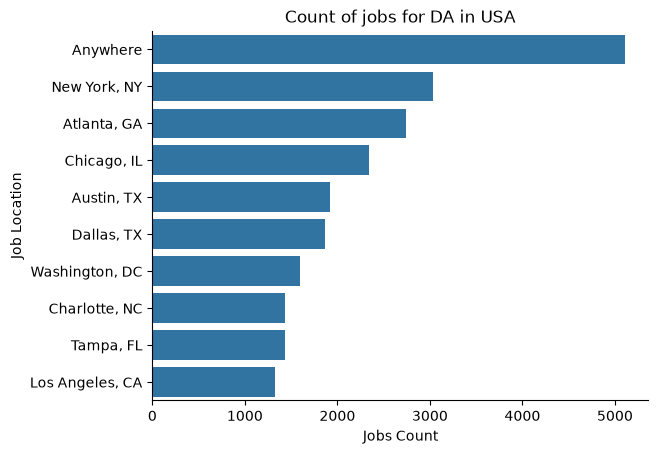

In [5]:
df_plot = df_usa_analyst['job_location'].value_counts().head(10).to_frame()

sns.barplot(data=df_plot, x='count', y='job_location')
sns.despine()
plt.title('Count of jobs for DA in USA')
plt.xlabel('Jobs Count')
plt.ylabel('Job Location')

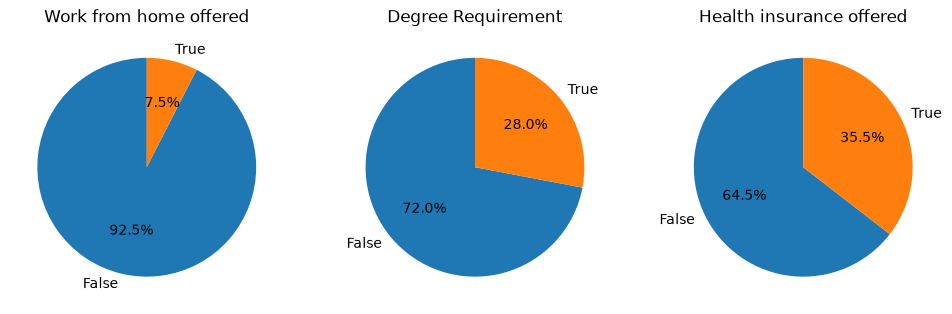

In [13]:
#Boolean values pie chart
dict_column = {
    'job_work_from_home': 'Work from home offered',
    'job_no_degree_mention': 'Degree Requirement',
    'job_health_insurance': 'Health insurance offered'
}

fig, ax = plt.subplots(1,3)
fig.set_size_inches((12,5))

for i, (column, title) in enumerate(dict_column.items()):
    ax[i].pie(df_usa_analyst[column].value_counts(), labels=['False', 'True'], autopct='%1.1f%%', startangle=90)
    ax[i].set_title(title)

plt.show()

Text(0, 0.5, 'Company Name')

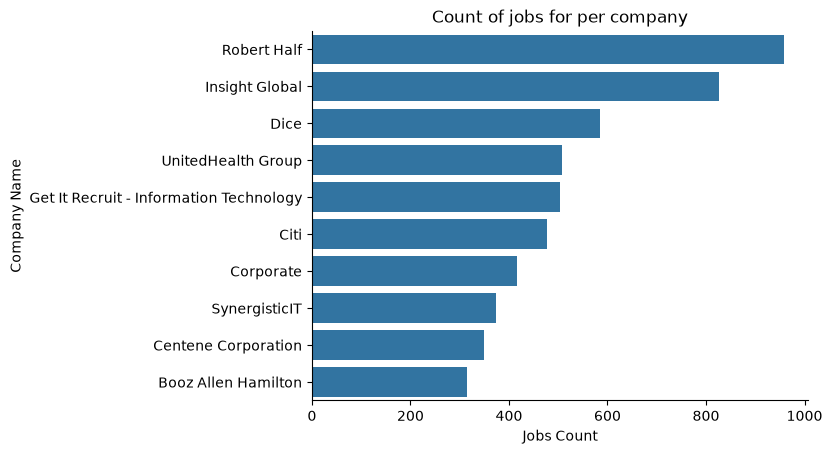

In [17]:
df_plot = df_usa_analyst['company_name'].value_counts().head(10).to_frame()

sns.barplot(data=df_plot, x='count', y='company_name')
sns.despine()
plt.title('Count of jobs for per company')
plt.xlabel('Jobs Count')
plt.ylabel('Company Name')